<img src='https://gitlab.eumetsat.int/eumetlab/oceans/ocean-training/tools/frameworks/-/raw/main/img/Standard_banner.png' align='right' width='100%'/>

<a href="../Index.ipynb" target="_blank"><< Index</a>
<br>
<a href="./1_8_OLCI_fluor.ipynb" target="_blank"><< Investigating OLCI fluorescence</a>&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;<a href="1_10_OLCI_light_environment.ipynb" target="_blank">Assessing the light environment >></a>

<font color="#138D75">**Copernicus Marine Training Service**</font> <br>
**Copyright:** 2026 European Union <br>
**License:** MIT <br>
**Authors:** Ben Loveday (EUMETSAT/Innoflair UG), Hayley Evers-King (EUMETSAT)

<html>
   <div style="float:left"><p>&emsp;</p></div>
   <div style="float:left"><a href="https://gitlab.eumetsat.int/eumetlab/oceans/ocean-training/sensors/learn-olci"><img src="https://img.shields.io/badge/open-EUMETLAB-E67E22.svg"></a></div>
   <div style="float:left"><p>&emsp;</p></div>
   <div style="float:left"><a href="https://user.eumetsat.int/data/themes/marine"><img src="https://img.shields.io/badge/open-USER PORTAL-154360.svg"></a></div>
   <div style="float:left"><p>&emsp;</p></div>
   <div style="float:left"><a href="https://mybinder.org/v2/git/https%3A%2F%2Fgitlab.eumetsat.int%2Feumetlab%2Foceans%2Focean-training%2Fsensors%2Flearn-olci/HEAD?labpath=1_OLCI_introductory%2F1_8_OLCI_iops.ipynb"><img src="https://mybinder.org/badge_logo.svg"></a></div>
   <div style="float:left"><p>&emsp;</p></div>
   <div style="float:left"><a href="https://jupyterhub.prod.wekeo2.eu/hub/user-redirect/lab/tree/public/wekeo4oceans/learn-olci/1_OLCI_introductory/1_8_OLCI_iops.ipynb"><img src="https://img.shields.io/badge/launch-WEKEO-1a4696.svg"></a></div>
   <div style="float:left"><p>&emsp;</p></div>
   <div style="float:left"><a href="https://jupyter.central.data.destination-earth.eu/"><img src="https://img.shields.io/badge/launch-DestinE_Stack-2596be.svg"></a></div></div>
   <div style="float:left"><p>&emsp;</p></div>
   <div style="float:left"><a href="https://code.insula.destine.eu/"><img src="https://img.shields.io/badge/launch-DestinE_Insula_Code-f43fd3.svg"></a></div></div>
</html>

<div class="alert alert-block alert-success">
<h3>Learn OLCI: Introductory</h3></div>

<div class="alert alert-block alert-warning">
    
<b>PREREQUISITES </b>
    
**One** of the following modules are prerequisites for this notebook, and will retrieve the data required here.
  - **<a href="./1_1a_OLCI_data_access_Data_Store.ipynb" target="_blank">1_1a_OLCI_data_access_Data_Store.ipynb</a>** if using the Data Store for data access
  - **<a href="./1_1b_OLCI_data_access_WEkEO_HDA.ipynb" target="_blank">1_1b_OLCI_data_access_WEkEO_HDA.ipynb</a>** if using WEkEO for data access
  - **<a href="./1_1c_OLCI_data_access_DEDL_HDA.ipynb" target="_blank">1_1b_OLCI_data_access_DEDL_HDA.ipynb</a>** if using DestinE for data access
    
</div>

<div class="alert alert-block alert-danger">
This notebook is suitable for working with OLCI level 1b products from baseline collection 004, and OLCI level 2 products from baseline collection 003. If you wish to work with OLCI level 2 products from baseline collection 004 please checkout the appropriate branch.
</div>

<hr>

# Exploring and visualising Sentinel-3 OLCI IOP products - WIP

### Data used

| Dataset | EUMETSAT collection ID| EUMETSAT collection<br>description | WEkEO dataset ID | WEkEO description |
|:--------------------:|:-----------------------:|:-------------:|:-----------------:|:-----------------:|
| Sentinel-3 OLCI level 2 full resolution | EO:EUM:DAT:0407 | <a href="https://user.eumetsat.int/catalogue/EO:EUM:DAT:SENTINEL-3:OL_2_WFR___NTC" target="_blank">Description</a> | EO:EUM:DAT:SENTINEL-3:OL_2_WFR___ | <a href="https://www.wekeo.eu/data?view=dataset&dataset=EO%3AEUM%3ADAT%3ASENTINEL-3%3AOL_2_WFR___" target="_blank">Description</a> |
| Sentinel-3 OLCI level 2 full resolution (version BC003) reprocessing | EO:EUM:DAT:0556 | <a href="https://user.eumetsat.int/catalogue/EO:EUM:DAT:0556" target="_blank">Description</a> | - | - |

### Learning outcomes

At the end of this notebook you will know;
* How to use the IOP products from OLCI baseline collection 004
* How to appropriately flag these properties
* How to plot these properties on a ternary diagram and map

### Outline

The interaction of light with natural waters is determined by the optical properties of the water itself and the substances contained within it. These interactions can be described using inherent optical properties (IOPs), which characterise how light is absorbed and scattered by the water and its constituents. Unlike apparent optical properties, such as reflectance, IOPs are independent of the ambient light field and depend only on the composition of the water.

The two fundamental IOPs are absorption and scattering. Absorption describes the removal of light as its energy is converted into other forms, while scattering describes changes in the direction of light as it interacts with molecules and particles in the water. The combined effects of absorption and scattering determine the spectral shape and magnitude of the water-leaving light that is ultimately observed by satellite ocean colour instruments.

Different components of the water contribute to these optical properties in different ways. Phytoplankton pigments, coloured dissolved and detrital matter, suspended particles, and the water itself each have characteristic absorption and scattering properties that vary with wavelength. By separating the total optical signal into contributions from these different components, IOP products can provide information about the composition of the water and the processes influencing its optical characteristics.

Retrieving IOPs from satellite observations requires the inversion of the relationship between the observed water-leaving reflectance and the underlying absorption and scattering properties. This is a more complex problem than applying a direct empirical relationship between reflectance and a single constituent concentration, but it provides a physically based framework for interpreting ocean colour observations across a wide range of water types.

In this notebook we'll explore a selection of IOPs derived from OLCI observations, examine what the different parameters represent, and investigate how their spatial distributions provide information about the optical composition of the water.

<div class="alert alert-info" role="alert">

## Table of contents

</div>
    
 1. [OLCI inherent optical property (IOP) products)](#OLCI-inherent-optical-property-(IOP)-products)
 1. [Reading absorption products](#Reading-absorption-products)
 1. [Understanding and applying flags](#Understanding-and-applying-flags)
 1. [Preparing plotting variables](#Preparing-plotting-variables) 
 1. [Plotting ternary diagrams](#Plotting-ternary-diagrams)
 1. [Applying your knowledge](#Applying-your-knowledge)

<hr>

We begin by importing all of the libraries that we need to run this notebook. If you have built your python using the environment file provided in this repository, then you should have everything you need. For more information on building environment, please see the repository **<a href="../README.md" target="_blank">README</a>**.

In [1]:
import cartopy.crs as ccrs                   # a library that support mapping
import xarray as xr                          # a library that supports the use of multi-dimensional arrays in Python
import glob                                  # a library that aids in searching for files
import os                                    # a library that allows us access to basic operating system commands like making directories
import matplotlib.pyplot as plt              # a library that support plotting
import matplotlib.ticker as mticker          # a library that extends plotting support
from matplotlib.colors import ListedColormap # a library that allows construction of colour maps
import matplotlib                            # a library that supports plotting
import eumartools                            # a EUMETSAT library that support working with Sentinel-3 products
import numpy as np                           # a library that provides support for array-based mathematics
import pandas as pd                          # a library that helps us create DataFrames
import warnings                              # a library that helps us manage warnings
warnings.filterwarnings('ignore')

# set plot font size
plt.rcParams.update({'font.size': 12})

We also need to import the plotly express module to make our ternary diagram. It can be a complicated package, so we don't include it in the main import but add it "on the fly".

In [2]:
try:
    import plotly.express as px
except:
    !pip install plotly-express
    import plotly.express as px

import plotly.io as pio
pio.renderers.default = 'notebook'

<div class="alert alert-info" role="alert">

## OLCI inherent optical property (IOP) products
[Table of contents](#Table-of-contents)

</div>

A range of inherent optical property (IOP) products are available for OLCI. These products were developed and evaluated through the EUMETSAT <a href="https://www.eumetsat.int/S3-OLCI-IOP" target="_blank">Sentinel-3 OLCI Inherent Optical Properties Science Study</a>, which investigated approaches for retrieving IOPs across the diverse optical conditions observed by OLCI.

The IOP products considered here are:

* `acdm_443` – absorption coefficient of coloured dissolved and detrital matter at 443 nm
* `acdom_443` – absorption coefficient of coloured dissolved organic matter at 443 nm
* `anw_443` – total non-water absorption coefficient at 443 nm
* `aphy_443` – phytoplankton absorption coefficient at 443 nm
* `bbp_443` – particulate backscattering coefficient at 443 nm
* `bbp_slope` – spectral slope of particulate backscattering

An additional product, `OWC`, provides the Optical Water Class associated with each pixel. The classification is based on the spectral characteristics of the ocean colour reflectance and provides a means of representing the diversity of optical water types observed by OLCI. The performance of individual IOP retrieval algorithms can vary considerably between different optical environments, and the Optical Water Classes therefore provide useful context for interpreting the retrieved IOPs and their associated uncertainties.

The absorption products describe the contributions of different optically active components to the absorption of light within the water. `aphy_443` represents absorption by phytoplankton at 443 nm, while `acdom_443` represents absorption by coloured dissolved organic matter. The `acdm_443` product represents the combined absorption associated with coloured dissolved and detrital matter. The `anw_443` product provides the total absorption by non-water components, representing the combined influence of optically active constituents other than the water itself.

The `bbp_443` product describes particulate backscattering at 443 nm. Backscattering is the component of scattering that redirects light back towards the surface and is therefore particularly important in determining the magnitude of the water-leaving signal observed by satellite instruments. The associated `bbp_slope` product describes the spectral dependence of particulate backscattering and can provide additional information about the characteristics of the particle population.

The IOP products are generated using algorithms selected and evaluated for different optical properties, including approaches described by Zhang et al., Loisel et al. (2018), and Bonelli et al. (2021). The products are accompanied by information on retrieval uncertainty for different Optical Water Classes, reflecting the fact that algorithm performance varies according to the optical characteristics of the water.

The absorption and backscattering coefficient products are stored as log10-scaled values. Care should therefore be taken when interpreting, visualising, or converting these variables, as the values stored in the products represent the logarithm of the corresponding coefficient rather than the coefficient directly. The `iop_flags` variable should also be used to identify retrieval failures for the different groups of IOP products before analysis or visualisation.

You can find additional information about Sentinel-3 OLCI level 2 products in the <a href="https://user.eumetsat.int/resources/user-guides/sentinel-3-ocean-colour-level-2-data-guide" target="_blank">Sentinel-3 ocean colour level 2 data guide</a> and the Sentinel-3 OLCI level 2 baseline collection 004 <a href="https://user.eumetsat.int/s3/ope-eup-strapi-media/S3_PN_OLCI_L2_M_004_00_Sentinel_3_Product_Notice_OLCI_Level_2_Water_v1_cfa434a623.pdf" target="_blank">product notice</a>.

<div class="alert alert-info" role="alert">

## Reading absorption products
[Table of contents](#Table-of-contents)

</div>

To begin with, we'll create paths that point to the location of our data of interest.

In [3]:
SAFE_directory = SAFE_directory = glob.glob(os.path.join(os.getcwd(), 'products', '*WFR*'))[0]

Next we'll set a parameter to reduce the resolution of the data we are working with. For analyses you would not want to do this, but it will help us to visualise our data much faster in the context of this tutorial notebook.

In [4]:
grid_reduce = 10

Then, we'll open our latitude and longitude grid, subsampling by `grid_reduce`.

In [5]:
geo_file = os.path.join(SAFE_directory,'geo_coordinates.nc')
geo_fid = xr.open_dataset(geo_file)
lon = geo_fid.longitude.data[::grid_reduce, ::grid_reduce]
lat = geo_fid.latitude.data[::grid_reduce, ::grid_reduce]
geo_fid.close()

We'll also open our IOP product, `iop_lsd.nn`.

*Note that there is a second IOP product, called `iop_nn.nc`. This second product contains the ADG443_NN absorption product that is derived from the neural network processor. The use of this product is discussed in the <a href="./1_7_OLCI_optical_constituents.ipynb" target="_blank">Exploring Sentinel-3 OLCI optical constituents</a> notebook.*

In [6]:
band_vars = xr.open_mfdataset(os.path.join(SAFE_directory,'iop_lsd.nc'))

<div class="alert alert-info" role="alert">

## Understanding and applying flags
[Back to top](#TOC_TOP_1_9)

</div>

As well as the data and the geocoordinates, to plot geophysical products derived from OLCI properly, we also need to extract and apply the relevant quality flags. Below you can see that the flags are extracted from the wqsf netcdf file. If we print out the flags and their associated bit values, you can get an idea about what they represent, and how to access each individual one.

In [7]:
flag_file = os.path.join(SAFE_directory,'wqsf.nc')
flag_vars = xr.open_dataset(flag_file)
band_vars["WQSF"] = flag_vars["WQSF"]

We'll use a quick function from the `eumartools` library that allows us to read in the flag information simply by supplying the name. For our recommendations on which flags to apply you should also consult the <a href="https://user.eumetsat.int/resources/user-guides/sentinel-3-olci-ocean-colour-processing-baseline" target="_blank">OLCI level 2 product notices</a> for the relevant processing baseline.

In [8]:
# reading masks: example land
land_mask = eumartools.flag_mask(flag_file, 'WQSF', ['LAND'])
land_mask = land_mask.astype(float)[::grid_reduce, ::grid_reduce]
land_mask[land_mask == 0.0] = np.nan

# reading masks: example cloud
cloud_mask = eumartools.flag_mask(flag_file, 'WQSF', ['CLOUD', 'CLOUD_AMBIGUOUS', 'CLOUD_MARGIN'])
cloud_mask = cloud_mask.astype(float)[::grid_reduce, ::grid_reduce]
cloud_mask[cloud_mask == 0.0] = np.nan

We'll create a combined mask by reading in all the flags that are relevant for the IOP product. These are the recommended flags provided by EUMETSAT.

In [9]:
# reading masks: all flags BAC recommended
IOP_mask = eumartools.flag_mask(flag_file, 'WQSF', ['LAND', 'CLOUD', 'CLOUD_AMBIGUOUS', 'CLOUD_MARGIN', 
                                                    'INVALID', 'COSMETIC', 'SATURATED', 'SUSPECT',
                                                    'HISOLZEN', 'HIGHGLINT', 'SNOW_ICE', 'AC_FAIL',
                                                    'WHITECAPS', 'ADJAC', 'RWNEG_O2', 'RWNEG_O3',
                                                    'RWNEG_O4', 'RWNEG_O5', 'RWNEG_O6', 'RWNEG_O7', 'RWNEG_O8',
                                                    'IOP_LSD_FAIL'])
IOP_mask = IOP_mask.astype(float)[::grid_reduce, ::grid_reduce]
IOP_mask[IOP_mask == 1.0] = np.nan
IOP_mask[IOP_mask == 0.0] = 1.0

Note that there is also a flag field, `iop_flags`, stored as a variable in the `iop_lsd.nc` product. We will make use of these, also.

In [10]:
iop_flags = np.array(band_vars.iop_flags[::grid_reduce, ::grid_reduce])
iop_flags[iop_flags != 0] = np.nan
iop_flags[iop_flags == 0] = 1

<div class="alert alert-info" role="alert">

## Preparing plotting variables
[Table of contents](#Table-of-contents)

</div>

To make our ternary plot, we need to preprepare some of our fields. We will begin by calculating the absorption due to non-algal particles (a$_{nap}$). We can calculate this as follows:

a$_{nap}$(λ) = a$_{cdm}$(λ) - a$_{cdom}$(λ) (<a href="https://www.sciencedirect.com/science/article/pii/S0034425721002571?via%3Dihub" target="_blank">Jorge, Daniel SF, et al., 2021</a>)

We will now construct our ternary plot using:

1. a$_{cdom}$(λ)
2. a$_{phy}$(λ)
3. a$_{nap}$(λ)

Note that, to make the ternary plot, we will shift the variables from log space to linear space, apply our masks, and reduce the grid accordingly.

In [11]:
a_cdom = 10**np.array(band_vars.acdom_443[::grid_reduce, ::grid_reduce]*IOP_mask*iop_flags)
a_phy = 10**np.array(band_vars.aphy_443[::grid_reduce, ::grid_reduce]*IOP_mask*iop_flags)
a_nap = 10**(np.array(band_vars.acdm_443[::grid_reduce, ::grid_reduce]*IOP_mask*iop_flags) \
           - np.array(band_vars.acdom_443[::grid_reduce, ::grid_reduce]*IOP_mask*iop_flags))

a_cdom[a_cdom < 0.0] = np.nan
a_nap[a_nap < 0.0] = np.nan
a_phy[a_phy < 0.0] = np.nan

Lets now identify where the dominant absorption component, so that we can plot the spatial variability.

In [12]:
stacked = np.stack([a_cdom, a_nap, a_phy], axis=0)
dominant_component = np.argmax(stacked, axis=0).astype(float)
dominant_component[np.any(np.isnan(stacked), axis=0)] = np.nan

Now we can make our spatial plot.

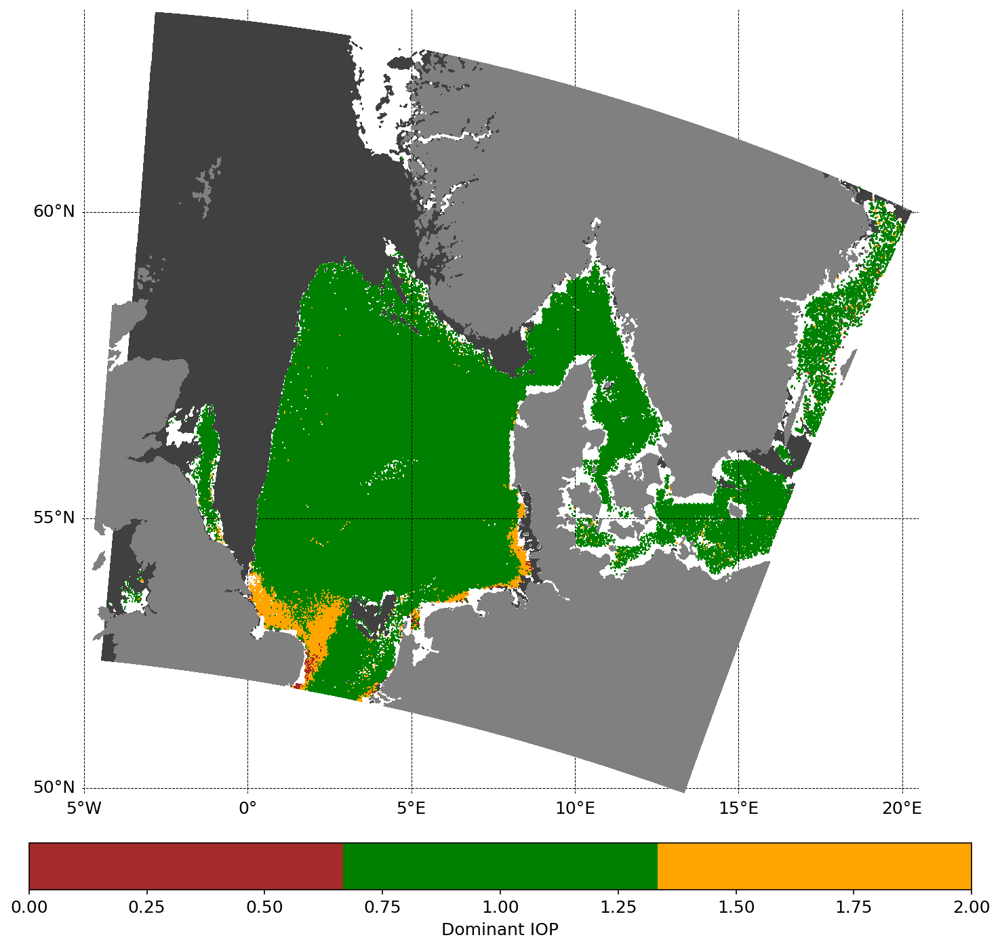

In [13]:
fig = plt.figure(figsize=(10, 10), dpi=150)
m = plt.subplot(projection=ccrs.Mercator())

p1 = m.pcolormesh(lon, lat, dominant_component, transform=ccrs.PlateCarree(), 
                  cmap = ListedColormap(['brown', 'green', 'orange']), vmin=0, vmax=2, zorder=1)

m.contourf(lon, lat, cloud_mask, levels=[0,1], transform=ccrs.PlateCarree(), colors='0.25', zorder=3)
m.contourf(lon, lat, land_mask, levels=[0,1], transform=ccrs.PlateCarree(), colors='0.5', zorder=4)

# Embellish with gridlines
g1 = m.gridlines(draw_labels = True, zorder=20, color='0.0', linestyle='--',linewidth=0.5)
g1.xlocator = mticker.FixedLocator(np.arange(-180, 180, 5))
g1.ylocator = mticker.FixedLocator(np.arange(-90, 90, 5))
g1.top_labels = False
g1.right_labels = False
g1.xlabel_style = {'color': 'black'}
g1.ylabel_style = {'color': 'black'}
m.set(facecolor = "1.0")
m.axis('off')

cbar = fig.colorbar(p1, location='bottom', pad=0.05)
cbar.set_label('Dominant IOP')

plt.tight_layout()
#plt.savefig('1_9_OLCI_IOP.png', bbox_inches='tight')

<div class="alert alert-info" role="alert">

## Plotting ternary diagrams
[Table of contents](#Table-of-contents)

</div>

Although we have plotted the dominant IOP, it is also useful to consider the distribution of the IOPs. This can be done via a ternary plot, which we will make below. Lets first create a `plotly` dataframe with our IOP data;

In [14]:
max_val = np.argmax(np.vstack([a_phy.flatten(), a_cdom.flatten(), a_nap.flatten()]), axis=0)
max_string = max_val.astype(str)
max_string[max_string == "0"] = "a_phy"
max_string[max_string == "1"] = "a_cdom"
max_string[max_string == "2"] = "a_nap"

df = pd.DataFrame({
    'a_phy': a_phy.flatten(),
    'a_cdom': a_cdom.flatten(),
    'a_nap': a_nap.flatten(),
    'Dominant component': max_string,
    'lon': lon.flatten(),
    'lat': lat.flatten()
})

Now we can make our IOP plot, while retaining the colour coding of the spatial plot

In [15]:
fig = px.scatter_ternary(df, a="a_phy", b="a_cdom", c="a_nap", color="Dominant component",
                         color_discrete_map = {"a_phy": "green", "a_cdom": "brown", "a_nap":"orange"},
                         hover_data=["a_phy", "a_cdom", "a_nap", "lon", "lat"],
                         width=1200, height=800)

fig.update_layout(
    font=dict(family='Arial', size=20, color='black'),
    ternary=dict(
        aaxis=dict(title=dict(text='$a_{phy}(λ)$', font=dict(size=30, color='green')), tickfont=dict(size=20, color='green'), linecolor='green'),
        baxis=dict(title=dict(text='$a_{cdom}(λ)$', font=dict(size=30, color='brown')), tickfont=dict(size=20, color='brown'), linecolor='brown'),
        caxis=dict(title=dict(text='$a_{nap}(λ)$', font=dict(size=30, color='orange')), tickfont=dict(size=20, color='orange'), linecolor='orange'),
        bgcolor='#eaecee')
    )
fig.show()

<div class="alert alert-info" role="alert">

## Applying your knowledge
[Table of contents](#Table-of-contents)

</div>

### What to try next?

* Try to adapt the above to a different area and see how the two chlorophyll retrieval algorithms differ for your region of interest

<hr>
<a href="../Index.ipynb" target="_blank"><< Index</a>
<br>
<a href="./1_8_OLCI_fluor.ipynb" target="_blank"><< Investigating OLCI fluorescence</a>&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;<a href="1_10_OLCI_light_environment.ipynb" target="_blank">Assessing the light environment >></a>
<hr>
<a href="https://gitlab.eumetsat.int/eumetlab/ocean" target="_blank">View on GitLab</a> | <a href="https://training.eumetsat.int/" target="_blank">EUMETSAT Training</a> | <a href=mailto:ops@eumetsat.int target="_blank">Contact helpdesk for support </a> | <a href=mailto:training@eumetsat.int target="_blank">Contact our training team to collaborate on and reuse this material</a></span></p>